
# Install Dependencies

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


# Import Libraries

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import seaborn as sns

%matplotlib inline

# Load Data

In [5]:
df = pd.read_csv('Salary_Data.csv')
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


# Exploratory Data Analysis

In [6]:
print(f"Dataset Shape: {df.shape}")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (6704, 6)
Number of Rows: 6704
Number of Columns: 6


In [7]:
display(df.head(10))
display(df.tail(10))

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
6694,27.0,Male,High School,Digital Marketing Manager,2.0,40000.0
6695,33.0,Female,Bachelor's Degree,Content Marketing Manager,7.0,90000.0
6696,28.0,Male,PhD,Sales Representative,4.0,55000.0
6697,51.0,Female,Master's Degree,Senior Product Marketing Manager,19.0,190000.0
6698,37.0,Male,Bachelor's Degree,Junior Sales Representative,6.0,75000.0
6699,49.0,Female,PhD,Director of Marketing,20.0,200000.0
6700,32.0,Male,High School,Sales Associate,3.0,50000.0
6701,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0
6702,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0
6703,26.0,Female,High School,Sales Executive,1.0,35000.0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


dataset has null values

In [9]:
display(df.describe())

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


## Missing Values

In [10]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
Age,2,0.029833
Gender,2,0.029833
Education Level,3,0.044749
Job Title,2,0.029833
Years of Experience,3,0.044749
Salary,5,0.074582


Empty salary rows is unexpected

## Duplicate Rows

In [11]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 4912


There is too many duplicate rows in the dataset

## Unique Values

In [12]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())
    print(df[column].unique()[:10])


Age
Unique Values: 41
[32. 28. 45. 36. 52. 29. 42. 31. 26. 38.]

Gender
Unique Values: 3
<StringArray>
['Male', 'Female', nan, 'Other']
Length: 4, dtype: str

Education Level
Unique Values: 7
<StringArray>
[       'Bachelor's',          'Master's',               'PhD',
                 nan, 'Bachelor's Degree',   'Master's Degree',
       'High School',               'phD']
Length: 8, dtype: str

Job Title
Unique Values: 193
<StringArray>
[    'Software Engineer',          'Data Analyst',        'Senior Manager',
       'Sales Associate',              'Director',     'Marketing Analyst',
       'Product Manager',         'Sales Manager', 'Marketing Coordinator',
      'Senior Scientist']
Length: 10, dtype: str

Years of Experience
Unique Values: 37
[ 5.  3. 15.  7. 20.  2. 12.  4.  1. 10.]

Salary
Unique Values: 444
[ 90000.  65000. 150000.  60000. 200000.  55000. 120000.  80000.  45000.
 110000.]


in dataset has non values

## Numerical distributions

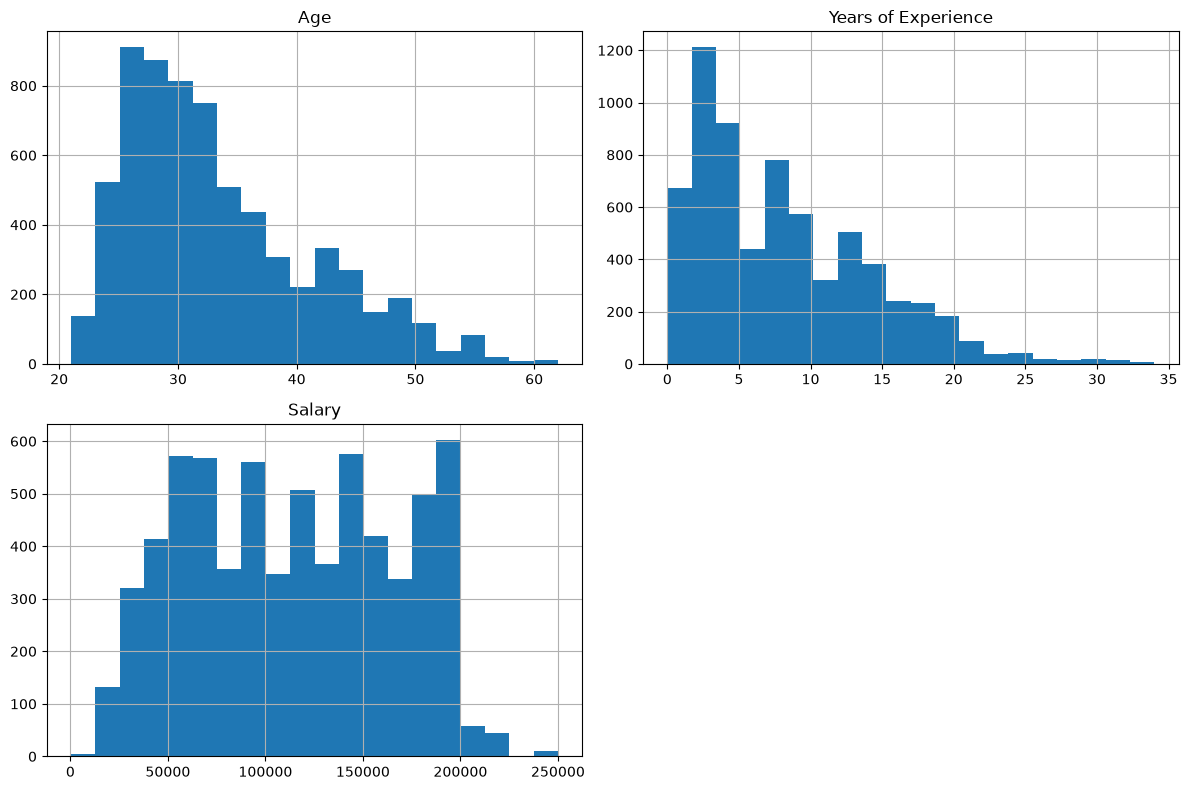

In [13]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

Age 22-34 </br>
Experience 0-5 </br>
Salary uneven distribution </br>


## Outliers

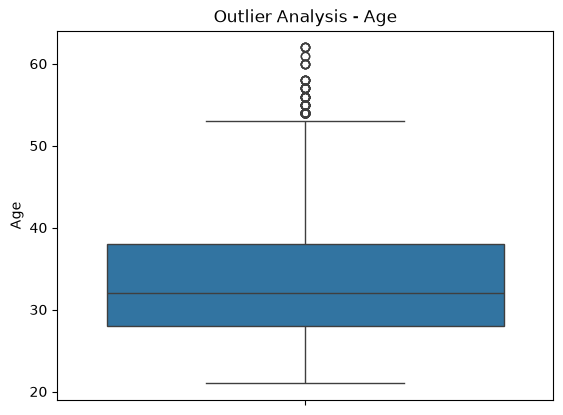

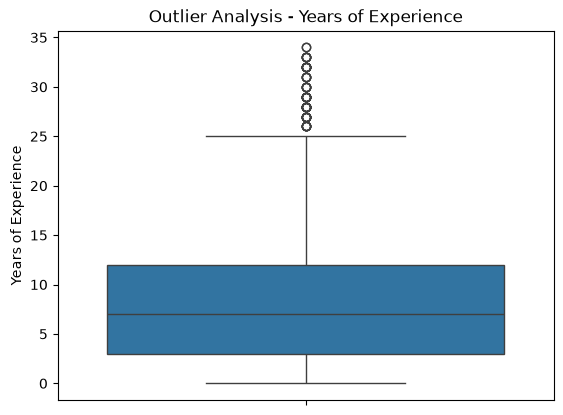

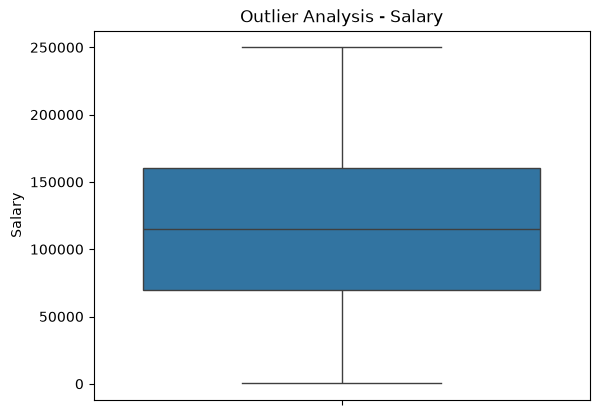

In [14]:
for column in df.select_dtypes(include=np.number).columns:
    sns.boxplot(data=df[column])
    plt.xticks(rotation=45)
    plt.title(f"Outlier Analysis - {column}")
    plt.show()



## Korrelation Matrix

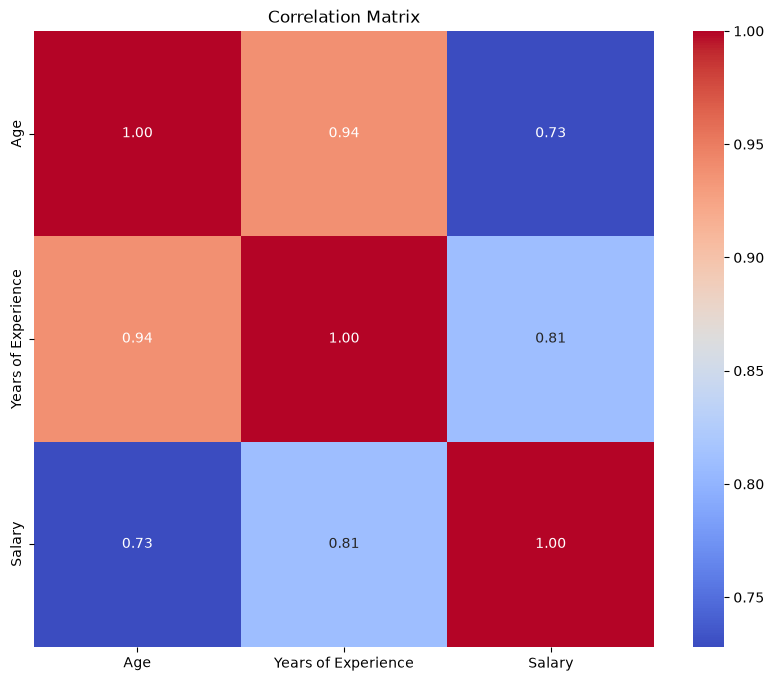

In [15]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

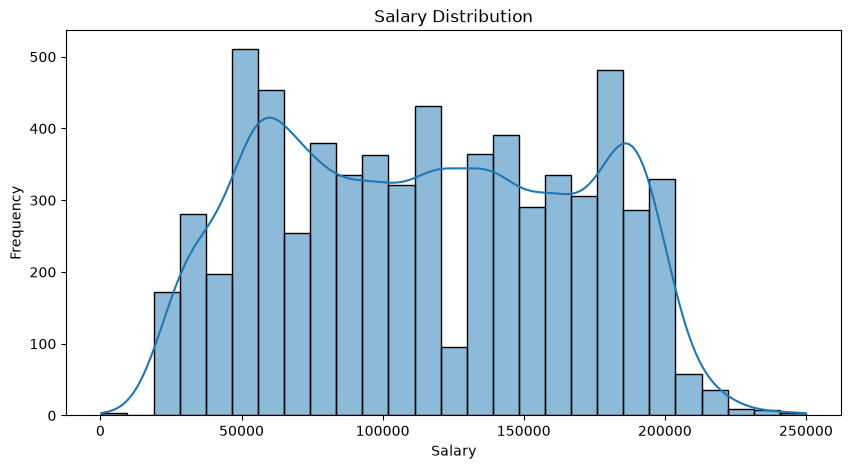

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Salary"], kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

# Data Cleaning

In [17]:
print(df.dtypes)
df.info()

Age                    float64
Gender                     str
Education Level            str
Job Title                  str
Years of Experience    float64
Salary                 float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


## Renaming Column Names

In [19]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
print(df.columns)

Index(['age', 'gender', 'education_level', 'job_title', 'years_of_experience',
       'salary'],
      dtype='str')


### Removing Rows without Salary

In [20]:
df = df.dropna(subset=["salary"]).copy()

### Normalize Categorical Text

In [21]:
for column in ["gender", "job_title", "education_level"]:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
    )

education_mapping = {
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
}

df["education_level"] = (
    df["education_level"]
    .replace(education_mapping)
)
print(df.columns.tolist())

['age', 'gender', 'education_level', 'job_title', 'years_of_experience', 'salary']


## Duplicate Values

In [22]:
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()))

Duplicate Rows: 4912


,age,gender,education_level,job_title,years_of_experience,salary
4884,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4897,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4910,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4923,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4936,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
...,...,...,...,...,...,...
1225,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1258,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1305,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1236,62.0,Male,PhD,Software Engineer Manager,20.0,200000.0


Duplicate rows should not be removed from the dataset. <br>
There may be more than one person of the same age, profession and experience

## Missing Values

In [23]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
age,0,0.00
gender,0,0.00
education_level,1,0.01
job_title,0,0.00
years_of_experience,0,0.00
salary,0,0.00


In [24]:
for line in df.iterrows():
    if line[1].isnull().values.any():
        print(f"Row {line[0]} has missing values: {line[1].isnull().values.sum()}")

Row 2011 has missing values: 1


### Cleaning Empty Rows

In [25]:
missing_per_row = df.isna().sum(axis=1)
rows_to_drop = missing_per_row[missing_per_row > 5].index

print(f"Rows to drop: {len(rows_to_drop)}")

Rows to drop: 0


In [27]:
df = df.drop(rows_to_drop)
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (6699, 6)


# Dataset Splitting

In [85]:
X = df.drop(columns=["salary"])
y = df["salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (5359, 5)
Test: (1340, 5)


# Preprocessing

In [86]:
numeric_features = [
    "age",
    "years_of_experience"
]

nominal_features = [
    "gender",
    "job_title"
]

ordinal_features = [
    "education_level"
]

### Filling Missing Valuee in Education Level Column

In [87]:
column_names = X_train.columns.tolist()

for line in X_train.iterrows():
    if line[1].isnull().values.any():
        columns_with_missing = [column_names[i] for i, is_null in enumerate(line[1].isnull().values) if is_null]
        print(f"Dataset: X_train, Row {line[0]} has missing values in columns: {columns_with_missing}")

column_names = X_test.columns.tolist()
for line in X_test.iterrows():
    if line[1].isnull().values.any():
        columns_with_missing = [column_names[i] for i, is_null in enumerate(line[1].isnull().values) if is_null]
        print(f"Dataset: X_test, Row {line[0]} has missing values in columns: {columns_with_missing}")

Dataset: X_train, Row 2011 has missing values in columns: ['education_level']


In [88]:
mfv_education_level = X_train['education_level'].mode()[0]

print("Most common education level:", mfv_education_level)

X_train['education_level'] = X_train['education_level'].fillna(mfv_education_level)
X_test['education_level'] = X_test['education_level'].fillna(mfv_education_level)

print("X_train empty values:", X_train['education_level'].isnull().sum())
print("X_test empty values:", X_test['education_level'].isnull().sum())

X_train.info()
X_test.info()

Most common education level: Bachelor's
X_train empty values: 0
X_test empty values: 0
<class 'pandas.DataFrame'>
Index: 5359 entries, 3861 to 862
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  5359 non-null   float64
 1   gender               5359 non-null   string 
 2   education_level      5359 non-null   string 
 3   job_title            5359 non-null   string 
 4   years_of_experience  5359 non-null   float64
dtypes: float64(2), string(3)
memory usage: 251.2 KB
<class 'pandas.DataFrame'>
Index: 1340 entries, 2460 to 2831
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1340 non-null   float64
 1   gender               1340 non-null   string 
 2   education_level      1340 non-null   string 
 3   job_title            1340 non-null   string 
 4   years_of_experience 

## Categorical Columns Processing

In [89]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(X_train[column].value_counts(dropna=False))


--- gender ---
gender
Male      2943
Female    2406
Other       10
Name: count, dtype: Int64

--- education_level ---
education_level
Bachelor's     2439
Master's       1477
PhD            1092
High School     351
Name: count, dtype: Int64

--- job_title ---
job_title
Software Engineer                 423
Data Scientist                    358
Software Engineer Manager         301
Data Analyst                      287
Senior Project Engineer           259
                                 ... 
Public Relations Manager            1
Junior UX Designer                  1
Junior Advertising Coordinator      1
Director of Product Management      1
Senior Account Executive            1
Name: count, Length: 168, dtype: Int64


### Label Encoding

"Gender" and "Job Title" columns are nominal categorical variables, so we will use one-hot encoding for these columns.<br>

"Education Level" column is an ordinal categorical variable, so we will use label encoding for this column. <br>

#### Gender

In [ ]:
X_train = pd.get_dummies(
    X_train,
    columns=["gender"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["gender"],
    drop_first=True,
    dtype=int
)

X_train columns after encoding: ['age', 'education_level', 'job_title', 'years_of_experience', 'gender_Male', 'gender_Other']


In [92]:
X_train.columns

Index(['age', 'education_level', 'job_title', 'years_of_experience',
       'gender_Male', 'gender_Other'],
      dtype='str')

In [93]:
X_train.head(10)

,age,education_level,job_title,years_of_experience,gender_Male,gender_Other
3861,26.0,Master's,Human Resources Coordinator,3.0,0,0
4940,28.0,PhD,Director of Marketing,6.0,0,0
135,39.0,Bachelor's,Administrative Assistant,10.0,0,0
6574,36.0,Bachelor's,Sales Director,6.0,1,0
3978,25.0,Bachelor's,Junior Software Developer,1.0,0,0
1556,43.0,PhD,Senior Project Engineer,13.0,1,0
6021,35.0,PhD,Research Director,12.0,0,0
4461,30.0,High School,Junior Sales Associate,1.0,0,0
3241,27.0,Bachelor's,Software Engineer,3.0,0,0
2133,27.0,Bachelor's,Back end Developer,3.0,1,0


#### Job Title

job_title
Software Engineer                518
Data Scientist                   453
Software Engineer Manager        376
Data Analyst                     363
Senior Project Engineer          318
                                ... 
Senior HR Specialist               1
Junior Operations Coordinator      1
Junior Financial Advisor           1
Developer                          1
Social Media Man                   1
Name: count, Length: 192, dtype: Int64


<Axes: xlabel='job_title', ylabel='count'>

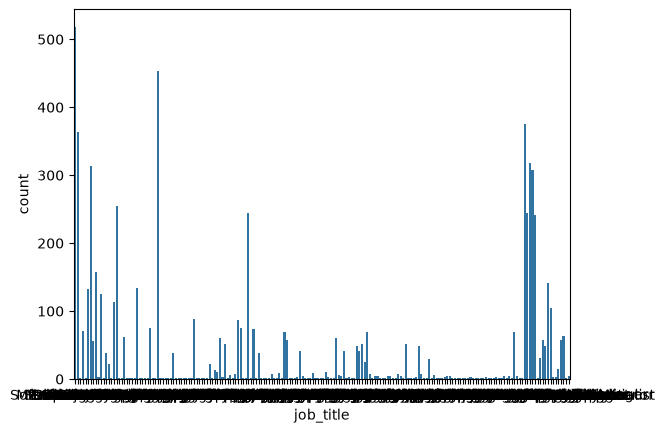

In [94]:
freq = df["job_title"].value_counts()
print(freq)

sns.countplot(data=df, x='job_title')

In [95]:
job_titles = df['job_title'].unique()

for title in job_titles:
    print(f"\n--- {title} ---")
    print(df[df['job_title'] == title]['job_title'].value_counts())


--- Software Engineer ---
job_title
Software Engineer    518
Name: count, dtype: Int64

--- Data Analyst ---
job_title
Data Analyst    363
Name: count, dtype: Int64

--- Senior Manager ---
job_title
Senior Manager    2
Name: count, dtype: Int64

--- Sales Associate ---
job_title
Sales Associate    70
Name: count, dtype: Int64

--- Director ---
job_title
Director    1
Name: count, dtype: Int64

--- Marketing Analyst ---
job_title
Marketing Analyst    132
Name: count, dtype: Int64

--- Product Manager ---
job_title
Product Manager    313
Name: count, dtype: Int64

--- Sales Manager ---
job_title
Sales Manager    56
Name: count, dtype: Int64

--- Marketing Coordinator ---
job_title
Marketing Coordinator    158
Name: count, dtype: Int64

--- Senior Scientist ---
job_title
Senior Scientist    3
Name: count, dtype: Int64

--- Software Developer ---
job_title
Software Developer    125
Name: count, dtype: Int64

--- HR Manager ---
job_title
HR Manager    2
Name: count, dtype: Int64

--- Finan

In [96]:
labels = {}

for title in job_titles:
    title = title.strip().lower().split()

    for word in title:
        if word not in labels:
            labels[word] = 1
        else:
            labels[word] += 1
labels = dict(sorted(labels.items(), key=lambda item: item[1], reverse=True))

print("Job Title Labels:", labels)

Job Title Labels: {'senior': 50, 'manager': 44, 'junior': 36, 'marketing': 21, 'analyst': 20, 'director': 20, 'of': 14, 'specialist': 14, 'operations': 13, 'sales': 12, 'coordinator': 12, 'engineer': 11, 'software': 10, 'data': 10, 'developer': 10, 'hr': 10, 'product': 9, 'business': 9, 'designer': 9, 'scientist': 8, 'financial': 8, 'project': 8, 'human': 8, 'resources': 7, 'customer': 6, 'it': 6, 'support': 5, 'social': 5, 'media': 5, 'development': 5, 'generalist': 4, 'ux': 4, 'account': 4, 'representative': 4, 'research': 4, 'associate': 3, 'service': 3, 'recruiter': 3, 'consultant': 3, 'accountant': 3, 'technical': 3, 'digital': 3, 'web': 3, 'advisor': 3, 'end': 3, 'rep': 2, 'vp': 2, 'success': 2, 'executive': 2, 'copywriter': 2, 'finance': 2, 'graphic': 2, 'researcher': 2, 'content': 2, 'chief': 2, 'officer': 2, 'principal': 2, 'supply': 2, 'chain': 2, 'training': 2, 'front': 2, 'juniour': 2, 'entry': 1, 'clerk': 1, 'ceo': 1, 'writer': 1, 'network': 1, 'administrative': 1, 'assist

In [97]:
job_groups = {
    "engineering": [
        "engineer", "developer", "software", "programmer",
        "architect", "devops", "network", "system"
    ],

    "data": [
        "data", "analyst", "scientist", "machine learning",
        "business intelligence", "statistician"
    ],

    "management": [
        "manager", "director", "chief", "executive",
        "supervisor", "president", "lead"
    ],

    "marketing": [
        "marketing", "seo", "content", "brand",
        "digital marketing", "social media"
    ],

    "sales": [
        "sales", "account executive", "account manager",
        "business development", "representative"
    ],

    "hr": [
        "human resources", "hr", "recruiter",
        "talent acquisition", "people"
    ],

    "design": [
        "designer", "design", "ux", "ui",
        "graphic", "creative"
    ],

    "other": []
}

job_title_text = df["job_title"].astype("string")

grouped_jobs = {}

for group_name, keywords in job_groups.items():
    for job_title in job_title_text:
        if any(keyword in job_title.lower() for keyword in keywords):
            if group_name not in grouped_jobs:
                grouped_jobs[group_name] = []
            grouped_jobs[group_name].append(job_title)
        else:
            grouped_jobs.setdefault("other", []).append(job_title)

    print(
        f"{group_name.title()} Job Titles: "
        f"{len(grouped_jobs[group_name])}"
    )

Engineering Job Titles: 2662
Data Job Titles: 1323
Management Job Titles: 2240
Marketing Job Titles: 1019
Sales Job Titles: 478
Hr Job Titles: 424
Design Job Titles: 116
Other Job Titles: 45330


In [98]:
job_title_mapping = {}

for category, group in grouped_jobs.items():
    for job_title in group:
        job_title_mapping[job_title] = category
        



X_train["job_title"] = X_train["job_title"].replace(job_title_mapping)
X_test["job_title"] = X_test["job_title"].replace(job_title_mapping)

In [99]:
print(f"X_train Job Title Value Counts:\n{X_train['job_title'].value_counts()}")

X_train Job Title Value Counts:
job_title
other         1920
management     909
data           901
marketing      827
sales          377
hr             334
design          91
Name: count, dtype: Int64


##### One-Hot Encoding for Job Title Column

In [100]:
X_train = pd.get_dummies(
    X_train,
    columns=["job_title"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["job_title"],
    drop_first=True,
    dtype=int
)

In [101]:
X_train.info()
X_train.head(10)

<class 'pandas.DataFrame'>
Index: 5359 entries, 3861 to 862
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   5359 non-null   float64
 1   education_level       5359 non-null   string 
 2   years_of_experience   5359 non-null   float64
 3   gender_Male           5359 non-null   int64  
 4   gender_Other          5359 non-null   int64  
 5   job_title_design      5359 non-null   int64  
 6   job_title_hr          5359 non-null   int64  
 7   job_title_management  5359 non-null   int64  
 8   job_title_marketing   5359 non-null   int64  
 9   job_title_other       5359 non-null   int64  
 10  job_title_sales       5359 non-null   int64  
dtypes: float64(2), int64(8), string(1)
memory usage: 502.4 KB


,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
3861,26.0,Master's,3.0,0,0,0,1,0,0,0,0
4940,28.0,PhD,6.0,0,0,0,0,0,1,0,0
135,39.0,Bachelor's,10.0,0,0,0,0,0,0,1,0
6574,36.0,Bachelor's,6.0,1,0,0,0,0,0,0,1
3978,25.0,Bachelor's,1.0,0,0,0,0,0,0,1,0
1556,43.0,PhD,13.0,1,0,0,0,0,0,1,0
6021,35.0,PhD,12.0,0,0,0,0,1,0,0,0
4461,30.0,High School,1.0,0,0,0,0,0,0,0,1
3241,27.0,Bachelor's,3.0,0,0,0,0,0,0,1,0
2133,27.0,Bachelor's,3.0,1,0,0,0,0,0,1,0


### Education Level

In [107]:
df.education_level.unique()

<StringArray>
['Bachelor's', 'Master's', 'PhD', <NA>, 'High School']
Length: 5, dtype: string

In [108]:
levels = ["nan", "High School", "Bachelor's", "Master's", "PhD"]

ordinal_encoder = OrdinalEncoder(categories=[levels], dtype=int)
X_train['education_level'] = ordinal_encoder.fit_transform(X_train[['education_level']])
X_test['education_level'] = ordinal_encoder.transform(X_test[['education_level']])

In [109]:
X_train.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
3861,26.0,3,3.0,0,0,0,1,0,0,0,0
4940,28.0,4,6.0,0,0,0,0,0,1,0,0
135,39.0,2,10.0,0,0,0,0,0,0,1,0
6574,36.0,2,6.0,1,0,0,0,0,0,0,1
3978,25.0,2,1.0,0,0,0,0,0,0,1,0
1556,43.0,4,13.0,1,0,0,0,0,0,1,0
6021,35.0,4,12.0,0,0,0,0,1,0,0,0
4461,30.0,1,1.0,0,0,0,0,0,0,0,1
3241,27.0,2,3.0,0,0,0,0,0,0,1,0
2133,27.0,2,3.0,1,0,0,0,0,0,1,0


In [110]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Train columns:", X_train.shape[1])
print("Test columns:", X_test.shape[1])

print(
    "Columns match:",
    X_train.columns.equals(X_test.columns)
)

Train columns: 11
Test columns: 11
Columns match: True


# Outlier Detection

In [111]:
numeric_columns = [
    "age",
    "years_of_experience",
    "salary"
]

## IQR

In [112]:
outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,28.0,38.0,10.0,13.0,53.0,123,1.84
1,years_of_experience,3.0,12.0,9.0,-10.5,25.5,75,1.12
2,salary,70000.0,160000.0,90000.0,-65000.0,295000.0,0,0.00


## Z-Score

In [113]:
from scipy.stats import zscore

for column in numeric_columns:

    z_scores = np.abs(zscore(df[column].dropna()))

    outlier_count = (z_scores > 3).sum()

    print(f"{column}: {outlier_count} outliers")

age: 28 outliers
years_of_experience: 68 outliers
salary: 0 outliers


# Scaling

In [114]:
scaling_columns = [
    "age",
    "years_of_experience"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scaling_columns] = scaler.fit_transform(X_train[scaling_columns])
X_test_scaled[scaling_columns] = scaler.transform(X_test[scaling_columns])

In [115]:
X_train_scaled.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
3861,-0.999239,3,-0.839811,0,0,0,1,0,0,0,0
4940,-0.735638,4,-0.342495,0,0,0,0,0,1,0,0
135,0.714167,2,0.320594,0,0,0,0,0,0,1,0
6574,0.318766,2,-0.342495,1,0,0,0,0,0,0,1
3978,-1.131039,2,-1.171356,0,0,0,0,0,0,1,0
1556,1.241369,4,0.817910,1,0,0,0,0,0,1,0
6021,0.186965,4,0.652138,0,0,0,0,1,0,0,0
4461,-0.472037,1,-1.171356,0,0,0,0,0,0,0,1
3241,-0.867438,2,-0.839811,0,0,0,0,0,0,1,0
2133,-0.867438,2,-0.839811,1,0,0,0,0,0,1,0


# Training Model

## Linear Regression

In [116]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ -9278.85, 10699.63, 42719.98,...,-27149.43,-14193.1 ,-37060.05]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','education_level','years_of_experience',...,'job_title_marketing', 'job_title_other','job_title_sales']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.019e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [117]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [118]:
X_test.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
2460,25.0,2,2.0,1,0,0,0,0,0,1,0
2230,36.0,2,8.0,1,0,0,0,1,0,0,0
5559,27.0,2,3.0,1,0,0,0,0,0,1,0
3080,24.0,2,2.0,1,0,0,0,0,0,1,0
265,29.0,2,1.5,0,0,0,0,0,0,0,1
698,27.0,2,4.0,1,0,0,0,0,0,1,0
6355,28.0,1,2.0,1,0,0,0,0,0,0,1
4080,32.0,2,6.0,1,0,0,0,1,0,0,0
3167,36.0,4,12.0,1,0,0,0,0,0,0,0
470,30.0,2,5.0,0,0,0,0,0,0,0,0


In [121]:
y_pred = linear_model.predict(X_test_scaled)

In [122]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Results
--------------------------------
MAE  : 19677.41
MSE  : 673683040.30
RMSE : 25955.40
R²   : 0.7630


In [123]:
comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

print(comparison.head(10))

      Actual Salary  Predicted Salary
2460        90249.0      78862.153966
2230       135000.0     117274.548590
5559        80000.0      83498.023748
3080        64182.0      80085.111414
265         40000.0      45322.013074
698        140000.0      90579.808425
6355        40000.0      41626.699977
4080        90000.0     108002.809027
3167       170000.0     171819.824461
470        145000.0     105945.354608


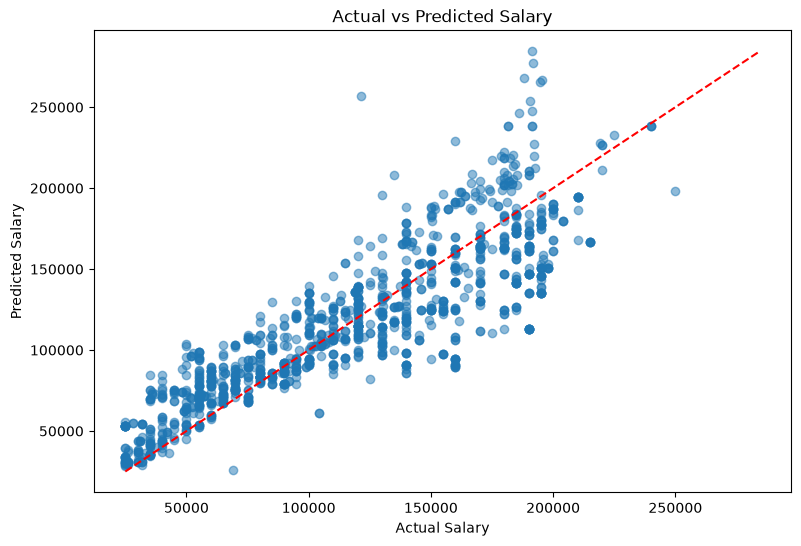

In [124]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

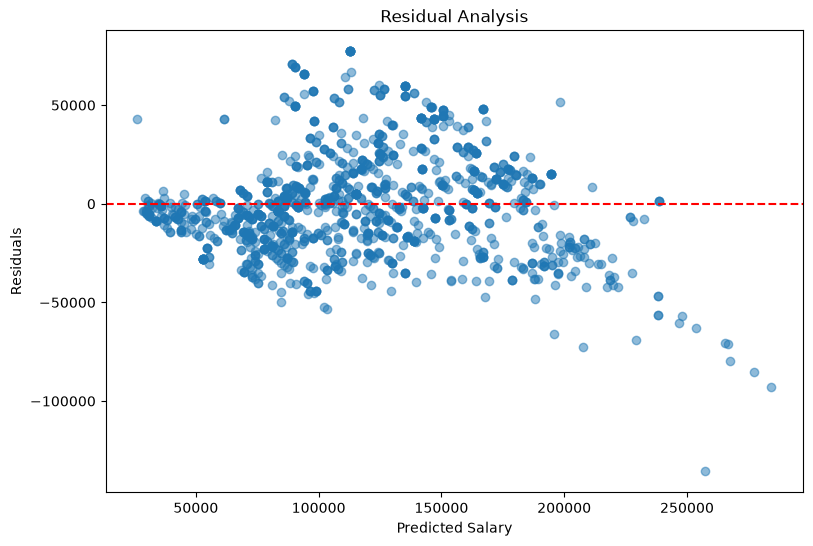

In [125]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

## Random Forest Regressor

In [137]:
random_forest_model = RandomForestRegressor(n_estimators=100, random_state=42)

random_forest_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [138]:
y_pred = random_forest_model.predict(X_test_scaled)

In [143]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Random Forest Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Random Forest Regression Model Results
--------------------------------
MAE  : 5180.36
MSE  : 123386916.60
RMSE : 11107.97
R²   : 0.9566


In [140]:
comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

print(comparison.head(10))

      Actual Salary  Predicted Salary
2460        90249.0      65329.758607
2230       135000.0     130422.884192
5559        80000.0      78308.083716
3080        64182.0      61747.835345
265         40000.0      31205.000000
698        140000.0     139929.048343
6355        40000.0      36020.438842
4080        90000.0      82745.965319
3167       170000.0     170000.000000
470        145000.0     145000.000000


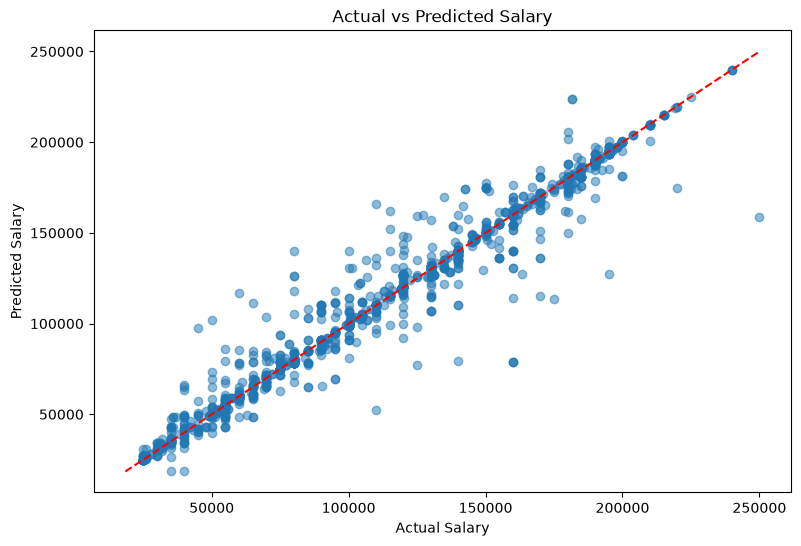

In [141]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

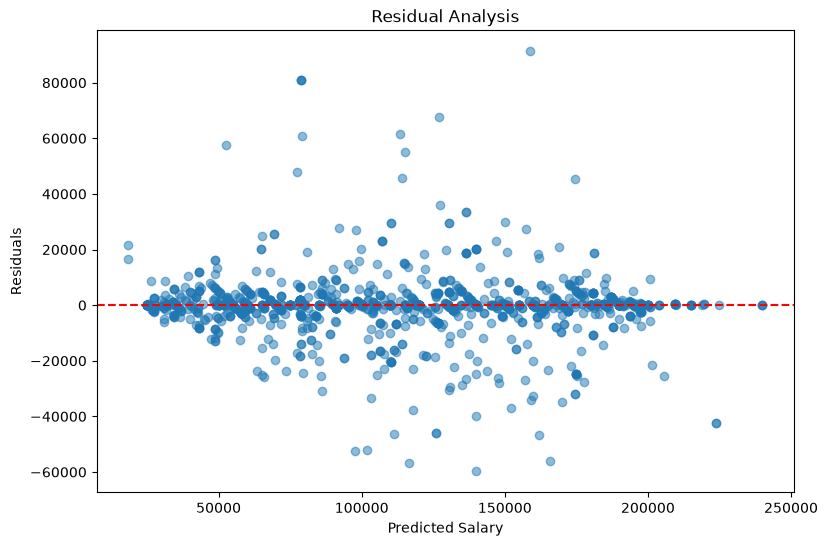

In [142]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()